## 1. Library import

In [44]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV

## 2. Data import

In [45]:
df_educational = pd.read_csv("ilc_scp03_linear_2_0.csv")

In [46]:
df_educational

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,frequenc,Frequency,acl00,Classification of activities for time use,isced11,...,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:ILC_SCP03(1.0),Persons participating in cultural or sport act...,A,Annual,1-3,From 1 to 3 times,AC521,Cinema,ED0-2,...,AL,Albania,2022,NaN,28.7,NaN,NaN,NaN,NaN,NaN
1,dataflow,ESTAT:ILC_SCP03(1.0),Persons participating in cultural or sport act...,A,Annual,1-3,From 1 to 3 times,AC521,Cinema,ED0-2,...,AT,Austria,2006,NaN,24.1,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:ILC_SCP03(1.0),Persons participating in cultural or sport act...,A,Annual,1-3,From 1 to 3 times,AC521,Cinema,ED0-2,...,AT,Austria,2015,NaN,29.8,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:ILC_SCP03(1.0),Persons participating in cultural or sport act...,A,Annual,1-3,From 1 to 3 times,AC521,Cinema,ED0-2,...,AT,Austria,2022,NaN,51.7,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:ILC_SCP03(1.0),Persons participating in cultural or sport act...,A,Annual,1-3,From 1 to 3 times,AC521,Cinema,ED0-2,...,BE,Belgium,2006,NaN,28.6,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
394123,dataflow,ESTAT:ILC_SCP03(1.0),Persons participating in cultural or sport act...,A,Annual,NM12,Not in the last 12 months,AC52A,"Cultural activities (cinema, live performances...",TOTAL,...,SK,Slovakia,2015,NaN,79.8,NaN,NaN,NaN,NaN,NaN
394124,dataflow,ESTAT:ILC_SCP03(1.0),Persons participating in cultural or sport act...,A,Annual,NM12,Not in the last 12 months,AC52A,"Cultural activities (cinema, live performances...",TOTAL,...,SK,Slovakia,2022,NaN,94.0,NaN,NaN,NaN,NaN,NaN
394125,dataflow,ESTAT:ILC_SCP03(1.0),Persons participating in cultural or sport act...,A,Annual,NM12,Not in the last 12 months,AC52A,"Cultural activities (cinema, live performances...",TOTAL,...,TR,Türkiye,2022,NaN,98.5,NaN,NaN,NaN,NaN,NaN
394126,dataflow,ESTAT:ILC_SCP03(1.0),Persons participating in cultural or sport act...,A,Annual,NM12,Not in the last 12 months,AC52A,"Cultural activities (cinema, live performances...",TOTAL,...,UK,United Kingdom,2006,NaN,50.5,NaN,NaN,NaN,NaN,NaN


In [47]:
df_ecomomical = pd.read_csv("ilc_scp04_linear_2_0.csv")

In [48]:
df_ecomomical

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,frequenc,Frequency,acl00,Classification of activities for time use,deg_urb,...,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:ILC_SCP04(1.0),Persons participating in in cultural or sport ...,A,Annual,1-3,From 1 to 3 times,AC521,Cinema,DEG1,...,AL,Albania,2022,NaN,1.5,NaN,NaN,NaN,NaN,NaN
1,dataflow,ESTAT:ILC_SCP04(1.0),Persons participating in in cultural or sport ...,A,Annual,1-3,From 1 to 3 times,AC521,Cinema,DEG1,...,AT,Austria,2015,NaN,29.0,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:ILC_SCP04(1.0),Persons participating in in cultural or sport ...,A,Annual,1-3,From 1 to 3 times,AC521,Cinema,DEG1,...,AT,Austria,2022,NaN,21.9,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:ILC_SCP04(1.0),Persons participating in in cultural or sport ...,A,Annual,1-3,From 1 to 3 times,AC521,Cinema,DEG1,...,BE,Belgium,2015,NaN,18.1,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:ILC_SCP04(1.0),Persons participating in in cultural or sport ...,A,Annual,1-3,From 1 to 3 times,AC521,Cinema,DEG1,...,BE,Belgium,2022,NaN,12.3,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
279355,dataflow,ESTAT:ILC_SCP04(1.0),Persons participating in in cultural or sport ...,A,Annual,NM12,Not in the last 12 months,AC52A,"Cultural activities (cinema, live performances...",TOTAL,...,SI,Slovenia,2015,NaN,29.9,NaN,NaN,NaN,NaN,NaN
279356,dataflow,ESTAT:ILC_SCP04(1.0),Persons participating in in cultural or sport ...,A,Annual,NM12,Not in the last 12 months,AC52A,"Cultural activities (cinema, live performances...",TOTAL,...,SI,Slovenia,2022,NaN,43.4,NaN,NaN,NaN,NaN,NaN
279357,dataflow,ESTAT:ILC_SCP04(1.0),Persons participating in in cultural or sport ...,A,Annual,NM12,Not in the last 12 months,AC52A,"Cultural activities (cinema, live performances...",TOTAL,...,SK,Slovakia,2015,NaN,40.6,NaN,NaN,NaN,NaN,NaN
279358,dataflow,ESTAT:ILC_SCP04(1.0),Persons participating in in cultural or sport ...,A,Annual,NM12,Not in the last 12 months,AC52A,"Cultural activities (cinema, live performances...",TOTAL,...,SK,Slovakia,2022,NaN,64.1,NaN,NaN,NaN,NaN,NaN


## 3. Data manupulation

### 3.1 df_educational

In [49]:
#Dropping technical columns
df_educational.drop(columns=["STRUCTURE", "STRUCTURE_ID", "STRUCTURE_NAME", "freq", "Time frequency", "Frequency", "acl00", "isced11", "age", "Sex", "unit", "Unit of measure", "geo", "Time"], inplace=True)
df_educational = df_educational.iloc[:, :8]

In [50]:
#Dropping all activity types except for Cultural activities (cinema, live performances or cultural sites)
df_educational = df_educational[df_educational["Classification of activities for time use"] == "Cultural activities (cinema, live performances or cultural sites)"]
df_educational.drop(columns=["Classification of activities for time use"], inplace=True)

#Dropping lines with aggregated sex data (sex == T) and geopolitical data (Geopolitical entity == European Union - 27 countries (from 2020))
df_educational = df_educational[df_educational["sex"] != "T"]
df_educational = df_educational[df_educational["Geopolitical entity (reporting)"] != "European Union - 27 countries (from 2020)"]
#Dropping lines with aggregated education level (ISCED == All ISCED levels)
df_educational = df_educational[df_educational["International Standard Classification of Education (ISCED 2011)"] != "All ISCED 2011 levels"]
#Dropping cumulative frequency category
df_educational = df_educational[df_educational["frequenc"] != "GE1"]
#Dropping redundant age groups
age_to_keep = ["From 16 to 24 years", "From 25 to 34 years", "From 35 to 44 years", "From 45 to 54 years", "From 55 to 64 years", "From 65 to 74 years", "From 75 to 84 years"]
df_educational = df_educational[df_educational["Age class"].isin(age_to_keep)]
df_educational["Age class"] = df_educational["Age class"].map({"From 16 to 24 years":"16-24", "From 25 to 34 years":"25-34", "From 35 to 44 years":"35-44", "From 45 to 54 years":"45-54", "From 55 to 64 years":"55-64", "From 65 to 74 years":"65-74", "From 75 to 84 years":"75-84"})

df_educational.rename(columns={"frequenc":"Frequency", "International Standard Classification of Education (ISCED 2011)":"Education level (ISCED)", "Age class":"Age", "sex":"Sex", "Geopolitical entity (reporting)":"Geopolitical entity", "OBS_VALUE":"Percentage"}, inplace=True)

#Convert education level string to ISCED level code
df_educational["Education level (ISCED)"] = df_educational["Education level (ISCED)"].map({"Less than primary, primary and lower secondary education (levels 0-2)":"0-2", "Upper secondary and post-secondary non-tertiary education (levels 3 and 4)": "3-4", "Tertiary education (levels 5-8)":"5-8"})

#Dropping lines with Nan values
df_educational.dropna(inplace=True)

#Renaming frequency labels
df_educational["Frequency"] = df_educational["Frequency"].replace({"NM12": "0", "GE4": "4+"})

In [51]:
df_educational

,Frequency,Education level (ISCED),Age,Sex,Geopolitical entity,TIME_PERIOD,Percentage
78624,1-3,0-2,16-24,F,Albania,2022,34.8
78626,1-3,0-2,16-24,F,Austria,2015,26.9
78627,1-3,0-2,16-24,F,Austria,2022,50.8
78629,1-3,0-2,16-24,F,Belgium,2015,29.8
78630,1-3,0-2,16-24,F,Belgium,2022,47.2
...,...,...,...,...,...,...,...
388265,0,5-8,75-84,M,Slovenia,2022,58.7
388266,0,5-8,75-84,M,Slovakia,2015,56.1
388267,0,5-8,75-84,M,Slovakia,2022,85.6
388268,0,5-8,75-84,M,Türkiye,2022,86.1


In [52]:
df_educational.describe(include="all")

,Frequency,Education level (ISCED),Age,Sex,Geopolitical entity,TIME_PERIOD,Percentage
count,8715,8715,8715,8715,8715,8715.000000,8715.000000
unique,3,3,7,2,36,NaN,NaN
top,0,3-4,65-74,M,Austria,NaN,NaN
freq,3231,2935,1350,4364,270,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,2017.704647,33.385749
std,NaN,NaN,NaN,NaN,NaN,4.438416,23.336882
min,NaN,NaN,NaN,NaN,NaN,2006.000000,0.000000
25%,NaN,NaN,NaN,NaN,NaN,2015.000000,14.600000
50%,NaN,NaN,NaN,NaN,NaN,2015.000000,30.700000
75%,NaN,NaN,NaN,NaN,NaN,2022.000000,46.700000


### 3.2 df_economical

In [53]:
#Dropping technical columns
df_ecomomical.drop(columns=["STRUCTURE", "STRUCTURE_ID", "STRUCTURE_NAME", "freq", "Time frequency","Frequency", "acl00", "deg_urb", "hhcomp", "Income quantile", "unit", "Unit of measure", "geo", "Time"], inplace=True)
df_ecomomical = df_ecomomical.iloc[:, :8]

In [54]:
#Dropping all activity types except for Cultural activities (cinema, live performances or cultural sites)
df_ecomomical = df_ecomomical[df_ecomomical["Classification of activities for time use"] == "Cultural activities (cinema, live performances or cultural sites)"]
df_ecomomical.drop(columns=["Classification of activities for time use"], inplace=True)

#Dropping aggregated geopolitical rows
df_ecomomical = df_ecomomical[df_ecomomical["Geopolitical entity (reporting)"] != "European Union - 27 countries (from 2020)"]
#Dropping aggregated urbanization, household and income rows
df_ecomomical = df_ecomomical[df_ecomomical["Degree of urbanisation"] != "Total"]
df_ecomomical = df_ecomomical[df_ecomomical["Household composition"] != "Total"]
df_ecomomical = df_ecomomical[df_ecomomical["quant_inc"] != "TOTAL"]
#Dropping cumulative frequency category
df_ecomomical = df_ecomomical[df_ecomomical["frequenc"] != "GE1"]

df_ecomomical.rename(columns={"frequenc": "Frequency", "quant_inc": "Income quintile", "Geopolitical entity (reporting)": "Geopolitical entity", "OBS_VALUE": "Percentage"}, inplace=True)

#Dropping lines with Nan values
df_ecomomical.dropna(inplace=True)

#Renaming frequen   cy labels
df_ecomomical["Frequency"] = df_ecomomical["Frequency"].replace({"NM12": "0", "GE4": "4+"})

In [55]:
df_ecomomical

,Frequency,Degree of urbanisation,Household composition,Income quintile,Geopolitical entity,TIME_PERIOD,Percentage
55872,1-3,Cities,One adult,QU1,Albania,2022,3.6
55873,1-3,Cities,One adult,QU1,Austria,2015,23.1
55874,1-3,Cities,One adult,QU1,Austria,2022,29.6
55875,1-3,Cities,One adult,QU1,Belgium,2015,18.8
55876,1-3,Cities,One adult,QU1,Belgium,2022,22.0
...,...,...,...,...,...,...,...
275415,0,Rural areas,Household without dependent children,QU5,Slovenia,2015,18.1
275416,0,Rural areas,Household without dependent children,QU5,Slovenia,2022,39.3
275417,0,Rural areas,Household without dependent children,QU5,Slovakia,2015,35.3
275418,0,Rural areas,Household without dependent children,QU5,Slovakia,2022,60.5


In [56]:
df_ecomomical.describe(include="all")

,Frequency,Degree of urbanisation,Household composition,Income quintile,Geopolitical entity,TIME_PERIOD,Percentage
count,19707,19707,19707,19707,19707,19707.000000,19707.000000
unique,3,3,9,5,33,NaN,NaN
top,1-3,Cities,Household without dependent children,QU2,Italy,NaN,NaN
freq,6569,6690,2757,4065,720,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,2018.478155,33.333349
std,NaN,NaN,NaN,NaN,NaN,3.500021,22.368351
min,NaN,NaN,NaN,NaN,NaN,2015.000000,0.000000
25%,NaN,NaN,NaN,NaN,NaN,2015.000000,15.900000
50%,NaN,NaN,NaN,NaN,NaN,2015.000000,30.200000
75%,NaN,NaN,NaN,NaN,NaN,2022.000000,46.400000


## 4. Monovariate desciption

### 4.1 df_educational

In [57]:
plt.style.use('default')
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': 'Times New Roman',
    'font.size': 12,
    'axes.facecolor': 'white',
    'figure.facecolor': 'white',
})

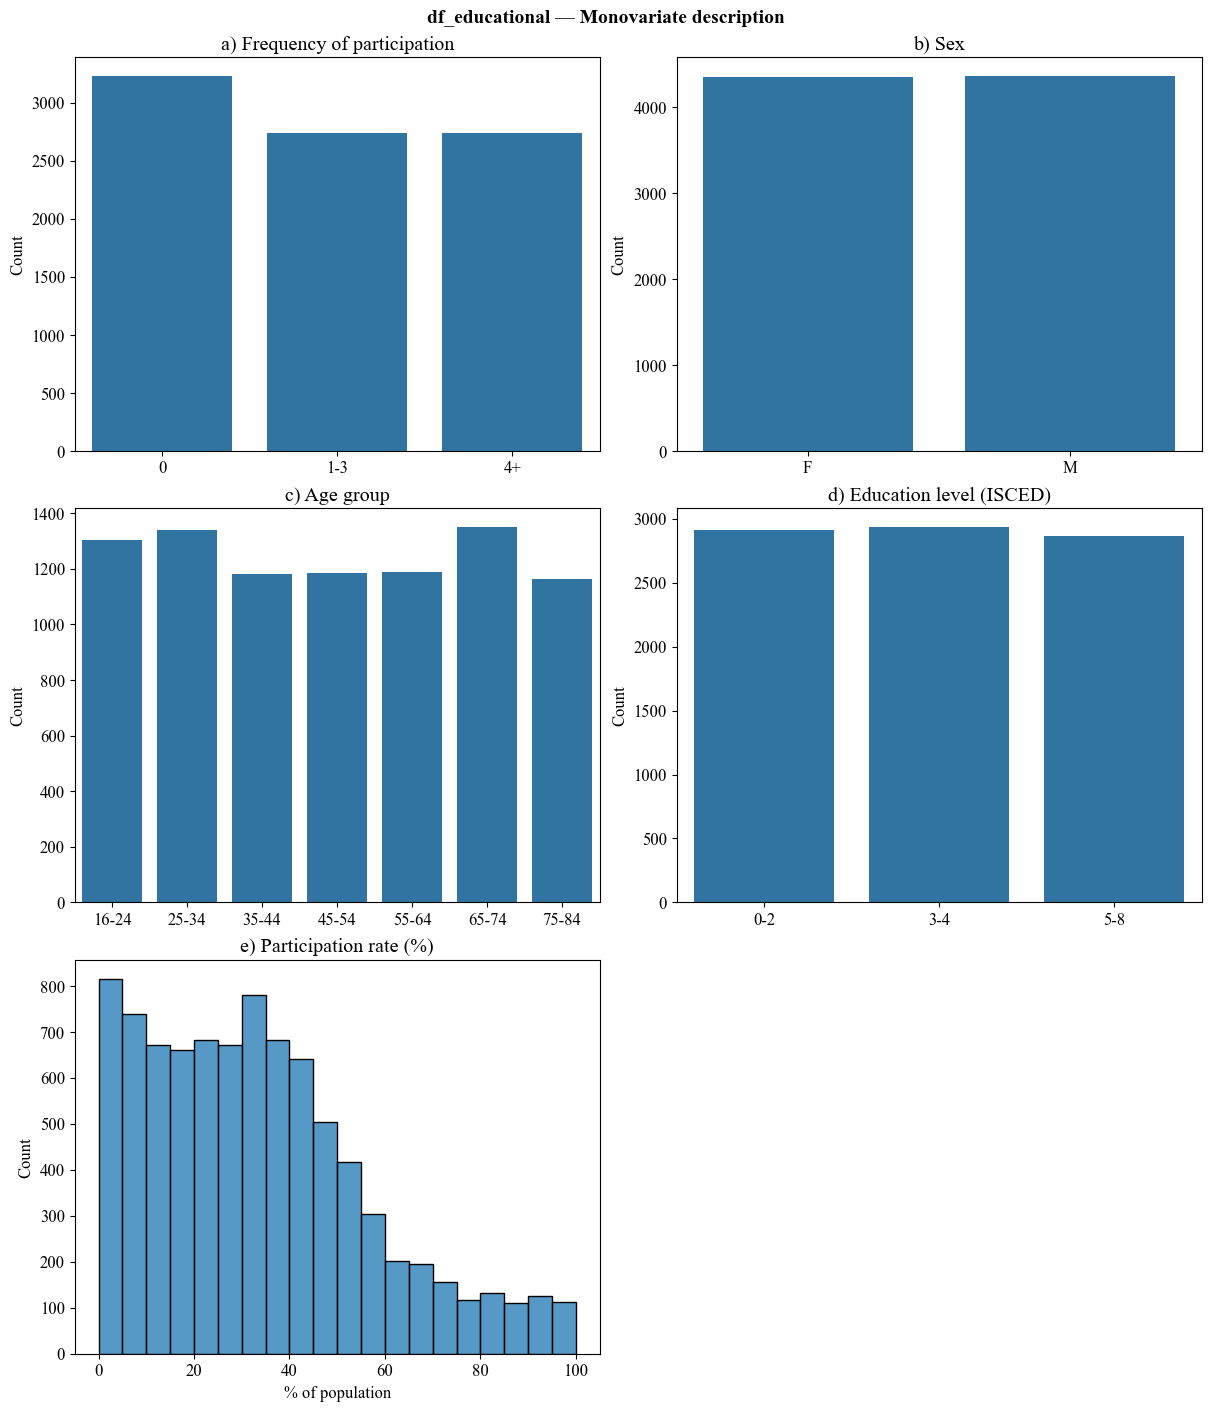

In [58]:
fig1, axes = plt.subplots(3, 2, figsize=(12, 14), constrained_layout=True)

# a) Frequency of participation
order_freq = ['0', '1-3', '4+']
sns.countplot(data=df_educational, x="Frequency", order=order_freq, ax=axes[0, 0])
axes[0, 0].set_title("a) Frequency of participation")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Count")

# b) Sex
sns.countplot(data=df_educational, x="Sex", ax=axes[0, 1])
axes[0, 1].set_title("b) Sex")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Count")

# c) Age group
order_age = ['16-24', '25-34', '35-44', '45-54', '55-64', '65-74', '75-84']
sns.countplot(data=df_educational, x="Age", order=order_age, ax=axes[1, 0])
axes[1, 0].set_title("c) Age group")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Count")

# d) Education level (ISCED)
order_edu = ['0-2', '3-4', '5-8']
sns.countplot(data=df_educational, x="Education level (ISCED)", order=order_edu, ax=axes[1, 1])
axes[1, 1].set_title("d) Education level (ISCED)")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Count")

# e) Participation rate (%)
sns.histplot(data=df_educational, x="Percentage", bins=20, ax=axes[2, 0])
axes[2, 0].set_title("e) Participation rate (%)")
axes[2, 0].set_xlabel("% of population")
axes[2, 0].set_ylabel("Count")

axes[2, 1].set_visible(False)

plt.suptitle("df_educational — Monovariate description", fontsize=14, fontweight='bold')
plt.show()

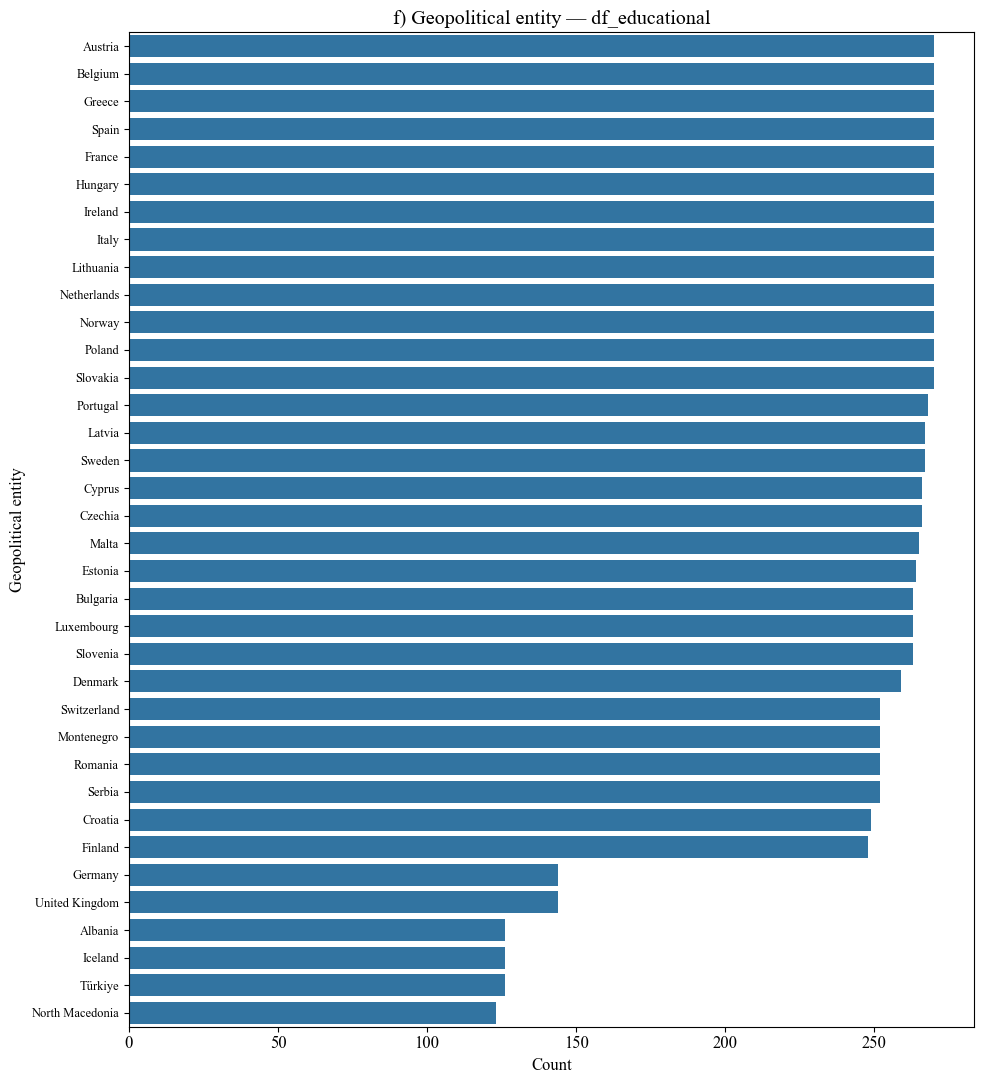

In [59]:
# f) Geopolitical entity
plt.figure(figsize=(10, 11))
country_counts = df_educational["Geopolitical entity"].value_counts()
sns.barplot(x=country_counts.values, y=country_counts.index)
plt.title("f) Geopolitical entity — df_educational")
plt.xlabel("Count")
plt.tick_params(axis='y', labelsize=9)
plt.tight_layout()
plt.show()

### 4.2 df_economical

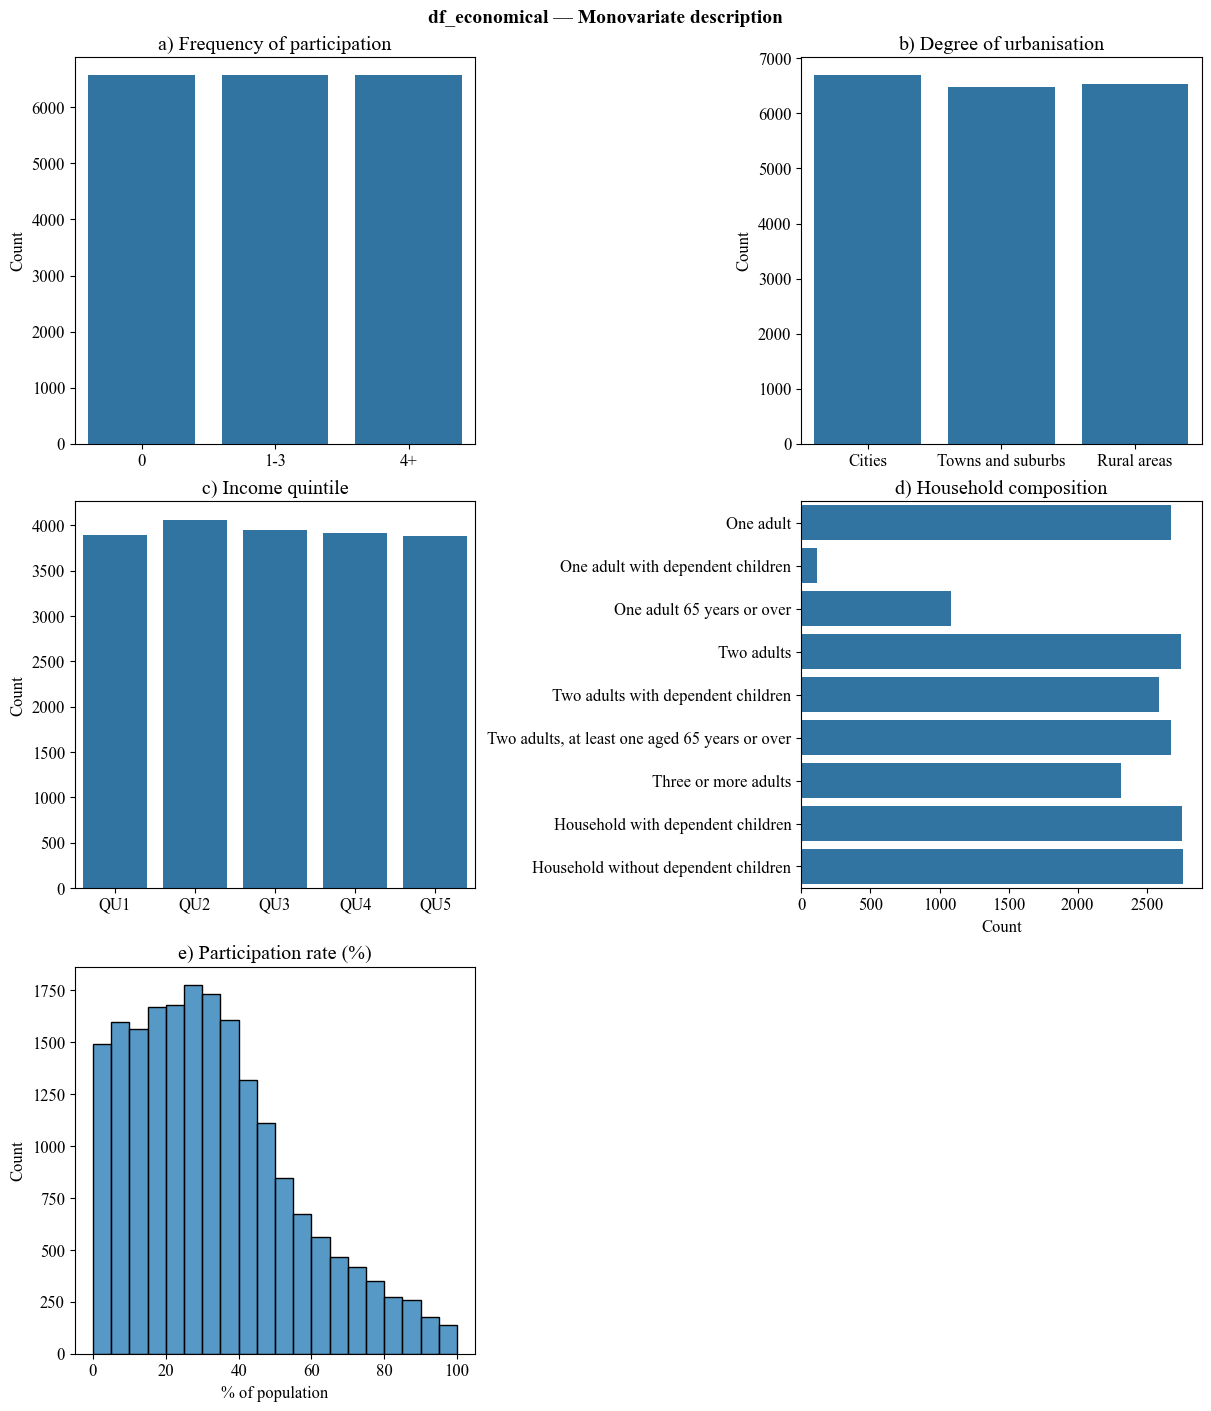

In [60]:
fig2, axes = plt.subplots(3, 2, figsize=(12, 14), constrained_layout=True)

# a) Frequency of participation
order_freq = ['0', '1-3', '4+']
sns.countplot(data=df_ecomomical, x="Frequency", order=order_freq, ax=axes[0, 0])
axes[0, 0].set_title("a) Frequency of participation")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Count")

# b) Degree of urbanisation
sns.countplot(data=df_ecomomical, x="Degree of urbanisation", ax=axes[0, 1])
axes[0, 1].set_title("b) Degree of urbanisation")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Count")

# c) Income quintile
order_inc = ['QU1', 'QU2', 'QU3', 'QU4', 'QU5']
sns.countplot(data=df_ecomomical, x="Income quintile", order=order_inc, ax=axes[1, 0])
axes[1, 0].set_title("c) Income quintile")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Count")

# d) Household composition
sns.countplot(data=df_ecomomical, y="Household composition", ax=axes[1, 1])
axes[1, 1].set_title("d) Household composition")
axes[1, 1].set_ylabel("")
axes[1, 1].set_xlabel("Count")

# e) Participation rate (%)
sns.histplot(data=df_ecomomical, x="Percentage", bins=20, ax=axes[2, 0])
axes[2, 0].set_title("e) Participation rate (%)")
axes[2, 0].set_xlabel("% of population")
axes[2, 0].set_ylabel("Count")

axes[2, 1].set_visible(False)

plt.suptitle("df_economical — Monovariate description", fontsize=14, fontweight='bold')
plt.show()

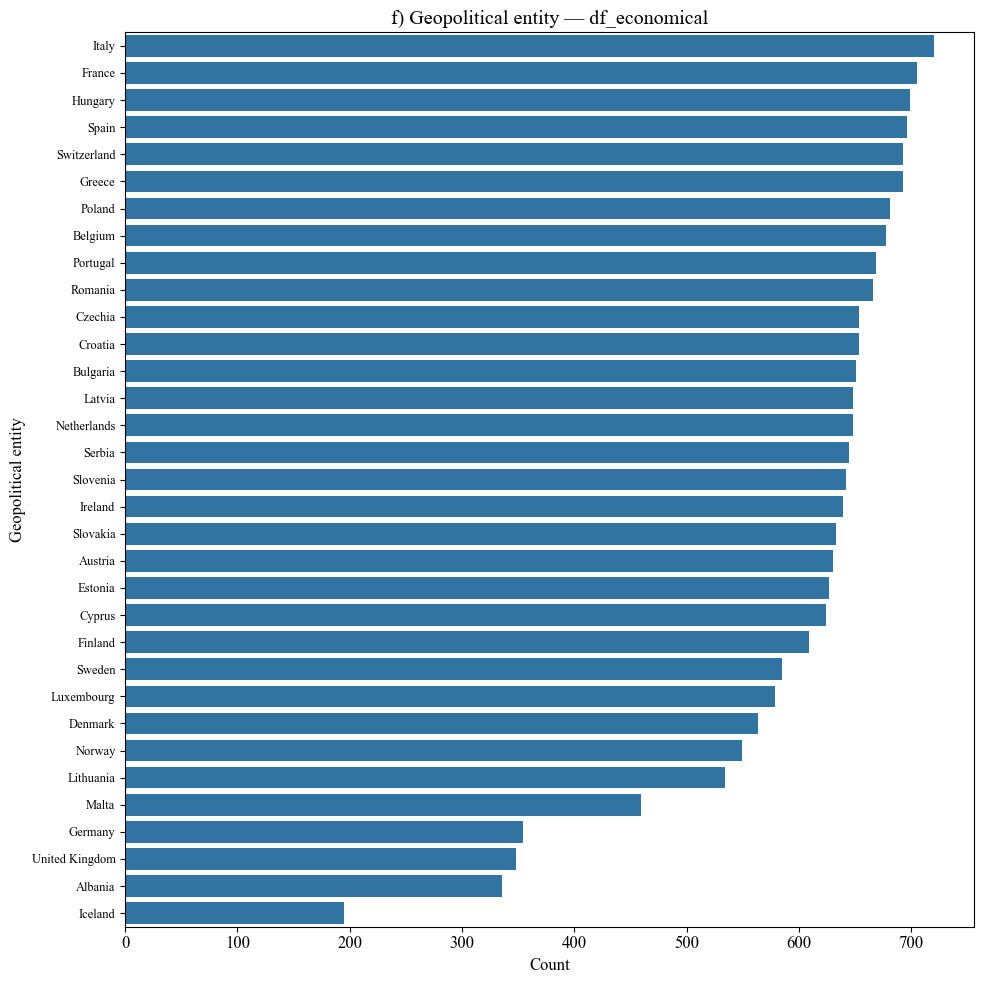

In [61]:
# f) Geopolitical entity
plt.figure(figsize=(10, 10))
country_counts = df_ecomomical["Geopolitical entity"].value_counts()
sns.barplot(x=country_counts.values, y=country_counts.index)
plt.title("f) Geopolitical entity — df_economical")
plt.xlabel("Count")
plt.tick_params(axis='y', labelsize=9)
plt.tight_layout()
plt.show()

## 5. Data standardization

### 5.1 df_educational

In [62]:
df_educational_unstandardized = df_educational.copy()

feature_cols = ['Education level (ISCED)', 'Age', 'Sex', 'Geopolitical entity']

# Median percentage for each feature+frequency combination to aggregate across time periods
df_agg = df_educational.groupby(feature_cols + ['Frequency'])['Percentage'].median().reset_index()

# For each feature combination keep only the frequency with the highest median percentage
idx = df_agg.groupby(feature_cols)['Percentage'].idxmax()
df_educational = df_agg.loc[idx].reset_index(drop=True)
df_educational.drop(columns=['Percentage'], inplace=True)

# Ordinal encoding of categorical variables
df_educational["Frequency"] = df_educational["Frequency"].map({"0": 0, "1-3": 1, "4+": 2})
df_educational["Sex"] = df_educational["Sex"].map({"M": 0, "F": 1})
df_educational["Education level (ISCED)"] = df_educational["Education level (ISCED)"].map({"0-2": 0, "3-4": 1, "5-8": 2})
df_educational["Age"] = df_educational["Age"].map({"16-24": 0, "25-34": 1, "35-44": 2, "45-54": 3, "55-64": 4, "65-74": 5, "75-84": 6})

# Grouping countries into macro-regions (done after pivot to preserve country-level granularity)
regions = {
    'Norway': 'North', 'Sweden': 'North', 'Finland': 'North', 'Denmark': 'North', 'Iceland': 'North',
    'France': 'West', 'Belgium': 'West', 'Netherlands': 'West', 'Luxembourg': 'West',
    'Germany': 'West', 'Austria': 'West', 'Switzerland': 'West', 'Ireland': 'West', 'United Kingdom': 'West',
    'Spain': 'South', 'Portugal': 'South', 'Italy': 'South', 'Greece': 'South', 'Cyprus': 'South', 'Malta': 'South',
    'Poland': 'East', 'Czechia': 'East', 'Slovakia': 'East', 'Hungary': 'East', 'Romania': 'East',
    'Bulgaria': 'East', 'Estonia': 'East', 'Latvia': 'East', 'Lithuania': 'East', 'Slovenia': 'East', 'Croatia': 'East',
    'Albania': 'Balkans', 'Serbia': 'Balkans', 'Montenegro': 'Balkans', 'North Macedonia': 'Balkans', 'Türkiye': 'Balkans'
}
df_educational['Region'] = df_educational['Geopolitical entity'].map(regions)
df_educational.drop(columns=['Geopolitical entity'], inplace=True)

# One-hot encoding of Region
df_educational = pd.get_dummies(df_educational, columns=['Region'], dtype=int)

In [63]:
df_educational

,Education level (ISCED),Age,Sex,Frequency,Region_Balkans,Region_East,Region_North,Region_South,Region_West
0,0,0,1,0,1,0,0,0,0
1,0,0,1,2,0,0,0,0,1
2,0,0,1,2,0,0,0,0,1
3,0,0,1,0,0,1,0,0,0
4,0,0,1,1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...
1499,2,6,0,0,0,0,0,1,0
1500,2,6,0,2,0,0,1,0,0
1501,2,6,0,2,0,0,0,0,1
1502,2,6,0,0,1,0,0,0,0


[]

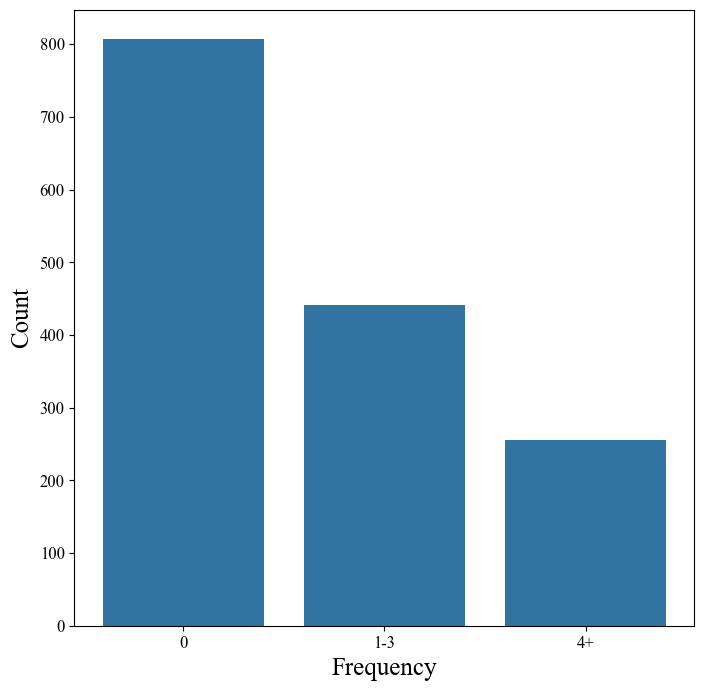

In [64]:
plt.figure(figsize=(8,8))
ax = sns.countplot(data=df_educational, x="Frequency")
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["0", "1-3", "4+"])
ax.set_xlabel("Frequency", fontsize=18)
ax.set_ylabel("Count", fontsize=18)
plt.plot()

### 5.2 df_economical

In [65]:
df_ecomomical_unstandardized = df_ecomomical.copy()

feature_cols_eco = ['Degree of urbanisation', 'Household composition', 'Income quintile', 'Geopolitical entity']

# Median percentage for each feature+frequency combination to aggregate across time periods
df_agg_eco = df_ecomomical.groupby(feature_cols_eco + ['Frequency'])['Percentage'].median().reset_index()

# For each feature combination keep only the frequency with the highest median percentage
idx_eco = df_agg_eco.groupby(feature_cols_eco)['Percentage'].idxmax()
df_ecomomical = df_agg_eco.loc[idx_eco].reset_index(drop=True)
df_ecomomical.drop(columns=['Percentage'], inplace=True)

# Ordinal encoding of categorical variables
df_ecomomical["Frequency"] = df_ecomomical["Frequency"].map({"0": 0, "1-3": 1, "4+": 2})
df_ecomomical["Degree of urbanisation"] = df_ecomomical["Degree of urbanisation"].map({"Rural areas": 0, "Towns and suburbs": 1, "Cities": 2})
df_ecomomical["Income quintile"] = df_ecomomical["Income quintile"].map({"QU1": 0, "QU2": 1, "QU3": 2, "QU4": 3, "QU5": 4})

# One-hot encoding for Household composition
df_ecomomical = pd.get_dummies(df_ecomomical, columns=['Household composition'], dtype=int)

# Grouping countries into macro-regions (done after pivot to preserve country-level granularity)
regions = {
    'Norway': 'North', 'Sweden': 'North', 'Finland': 'North', 'Denmark': 'North', 'Iceland': 'North',
    'France': 'West', 'Belgium': 'West', 'Netherlands': 'West', 'Luxembourg': 'West',
    'Germany': 'West', 'Austria': 'West', 'Switzerland': 'West', 'Ireland': 'West', 'United Kingdom': 'West',
    'Spain': 'South', 'Portugal': 'South', 'Italy': 'South', 'Greece': 'South', 'Cyprus': 'South', 'Malta': 'South',
    'Poland': 'East', 'Czechia': 'East', 'Slovakia': 'East', 'Hungary': 'East', 'Romania': 'East',
    'Bulgaria': 'East', 'Estonia': 'East', 'Latvia': 'East', 'Lithuania': 'East', 'Slovenia': 'East', 'Croatia': 'East',
    'Albania': 'Balkans', 'Serbia': 'Balkans', 'Montenegro': 'Balkans', 'North Macedonia': 'Balkans', 'Türkiye': 'Balkans'
}
df_ecomomical['Region'] = df_ecomomical['Geopolitical entity'].map(regions)
df_ecomomical.drop(columns=['Geopolitical entity'], inplace=True)

# One-hot encoding of Region
df_ecomomical = pd.get_dummies(df_ecomomical, columns=['Region'], dtype=int)

In [66]:
df_ecomomical

,Degree of urbanisation,Income quintile,Frequency,Household composition_Household with dependent children,Household composition_Household without dependent children,Household composition_One adult,Household composition_One adult 65 years or over,Household composition_One adult with dependent children,Household composition_Three or more adults,Household composition_Two adults,Household composition_Two adults with dependent children,"Household composition_Two adults, at least one aged 65 years or over",Region_Balkans,Region_East,Region_North,Region_South,Region_West
0,2,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0
1,2,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
2,2,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
3,2,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0
4,2,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3613,1,4,2,0,0,0,0,0,0,0,0,1,0,1,0,0,0
3614,1,4,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
3615,1,4,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0
3616,1,4,2,0,0,0,0,0,0,0,0,1,0,0,0,0,1


[]

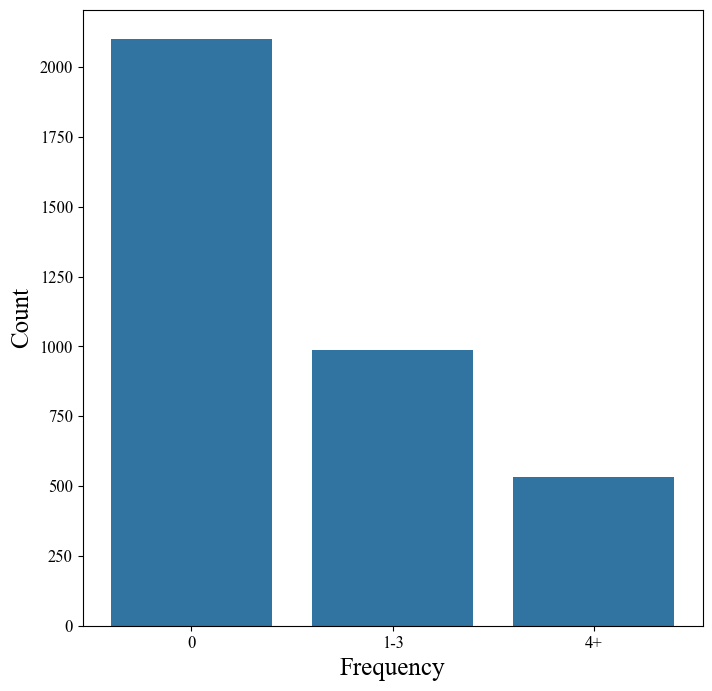

In [67]:
plt.figure(figsize=(8,8))
ax = sns.countplot(data=df_ecomomical, x="Frequency", )
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["0", "1-3", "4+"])
ax.set_xlabel("Frequency", fontsize=18)
ax.set_ylabel("Count", fontsize=18)
plt.plot()

## 6. Train/test split

### 6.1 df_educational

In [68]:
# Splitting df_education into train and test

X_1 = df_educational.drop("Frequency", axis=1)
y_1 = df_educational["Frequency"]

X_1_train, X_1_test, y_1_train, y_1_test = train_test_split(X_1, y_1, test_size = 0.25, random_state = 777)

### 6.2 df_economical

In [69]:
# Splitting df_economical into train and test

X_2 = df_ecomomical.drop("Frequency", axis=1)
y_2 = df_ecomomical["Frequency"]

X_2_train, X_2_test, y_2_train, y_2_test = train_test_split(X_2, y_2, test_size = 0.25, random_state = 777)

## 7. Modeling

### 7.1 df_educational

#### 7.1.1 Logistic regression

##### 7.1.1.1 Train

In [70]:
# Training logistic regression
reg = LogisticRegression(random_state=42)
reg.fit(X_1_train, y_1_train)

# Logistic regression model summary
coef = pd.DataFrame(reg.coef_, index=["0", "1-3", "4+"], columns=X_1_train.columns)
coef

,Education level (ISCED),Age,Sex,Region_Balkans,Region_East,Region_North,Region_South,Region_West
0,-1.903445,0.696805,-0.365790,2.982994,0.499621,-2.467444,0.271964,-1.284428
1-3,0.389707,-0.317225,0.136072,-0.759734,-0.069802,1.046896,-0.122083,-0.095709
4+,1.513738,-0.379580,0.229718,-2.223260,-0.429819,1.420548,-0.149881,1.380137


In [71]:
# Evaluate the accuracy and F1 metric for logistic regression model
y_1_pred = reg.predict(X_1_train)

print(classification_report(y_1_train, y_1_pred, target_names=["0", "1-3", "4+"]))
print(f"\nOverall accuracy: {accuracy_score(y_1_train, y_1_pred)}")

              precision    recall  f1-score   support

           0       0.85      0.91      0.88       612
         1-3       0.61      0.60      0.60       319
          4+       0.63      0.49      0.55       197

    accuracy                           0.75      1128
   macro avg       0.69      0.67      0.68      1128
weighted avg       0.74      0.75      0.74      1128


Overall accuracy: 0.750886524822695


##### 7.1.1.2 Test

In [72]:
# Test the logistic regression
y_1_pred = reg.predict(X_1_test)

print(classification_report(y_1_test, y_1_pred, target_names=["0", "1-3", "4+"]))
print(f"\nOverall accuracy: {accuracy_score(y_1_test, y_1_pred)}")

              precision    recall  f1-score   support

           0       0.88      0.91      0.89       195
         1-3       0.66      0.66      0.66       122
          4+       0.57      0.51      0.54        59

    accuracy                           0.76       376
   macro avg       0.70      0.69      0.70       376
weighted avg       0.76      0.76      0.76       376


Overall accuracy: 0.7632978723404256


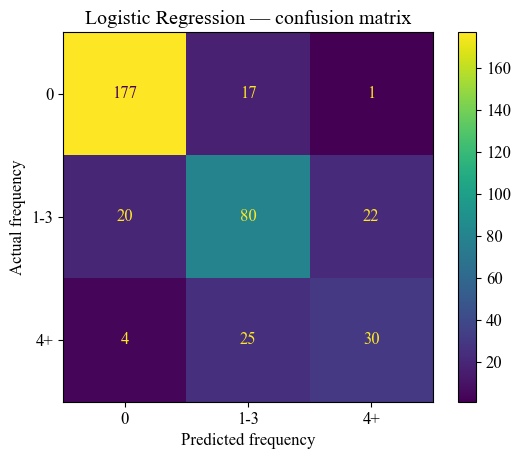

In [73]:
ConfusionMatrixDisplay.from_predictions(
    y_1_test, y_1_pred,
    display_labels=['0', '1-3', '4+']
)
plt.title("Logistic Regression — confusion matrix")
plt.xlabel("Predicted frequency")
plt.ylabel("Actual frequency")
plt.show()

##### 7.1.1.3 Bias/variance diagnostic

The accuracy score calculated on the training dataset is 0.750, and that calculated on the test dataset is 0.763. There therefore appears to be a fairly low bias and a very low variance.

#### 7.1.2 Random forest

##### 7.1.2.1 Choosing parameters

In [74]:
# Using GridSearchCV to find best parameters for RandomForestClassifier model
param_grid = {
    'max_depth' : [3,5,7,None],
    'min_samples_leaf' : [1,5,10,15]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_1_train, y_1_train)

print("Best parameters", grid.best_params_)

Best parameters {'max_depth': 7, 'min_samples_leaf': 5}


##### 7.1.2.2 Train

In [75]:
# Training random forest classifier with max_depth=7 and min_samples_leaf=5
forest = RandomForestClassifier(max_depth=7, min_samples_leaf=5, random_state=42)
forest.fit(X_1_train, y_1_train, sample_weight=None)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [76]:
# Evaluate the error of random forest classifier
y_1_pred = forest.predict(X_1_train)

print(f"{classification_report(y_1_train, y_1_pred, target_names=["0", "1-3", "4+"])}")

# Importance of each variable
importances = pd.Series(forest.feature_importances_, index=X_1_train.columns)
print(f"\nImportance of each variable\n\n{importances.sort_values()}")

print(f"\nOverall accuracy: {accuracy_score(y_1_train, y_1_pred)}")

              precision    recall  f1-score   support

           0       0.87      0.93      0.90       612
         1-3       0.68      0.73      0.70       319
          4+       0.81      0.55      0.65       197

    accuracy                           0.81      1128
   macro avg       0.79      0.74      0.75      1128
weighted avg       0.81      0.81      0.80      1128


Importance of each variable

Region_South               0.018289
Sex                        0.024297
Region_East                0.033309
Region_Balkans             0.086028
Region_West                0.090210
Region_North               0.093315
Education level (ISCED)    0.311444
Age                        0.343109
dtype: float64

Overall accuracy: 0.8058510638297872


##### 7.1.2.3 Test

In [77]:
# Test the random forest classifier
y_1_pred = forest.predict(X_1_test)

print(f"{classification_report(y_1_test, y_1_pred, target_names=["0", "1-3", "4+"])}")

# Importance of each variable
importances = pd.Series(forest.feature_importances_, index=X_1_test.columns)
print(f"\nImportance of each variable\n\n{importances.sort_values()}")

print(f"\nOverall accuracy: {accuracy_score(y_1_test, y_1_pred)}")

              precision    recall  f1-score   support

           0       0.91      0.93      0.92       195
         1-3       0.72      0.75      0.74       122
          4+       0.69      0.56      0.62        59

    accuracy                           0.82       376
   macro avg       0.77      0.75      0.76       376
weighted avg       0.81      0.82      0.81       376


Importance of each variable

Region_South               0.018289
Sex                        0.024297
Region_East                0.033309
Region_Balkans             0.086028
Region_West                0.090210
Region_North               0.093315
Education level (ISCED)    0.311444
Age                        0.343109
dtype: float64

Overall accuracy: 0.8164893617021277


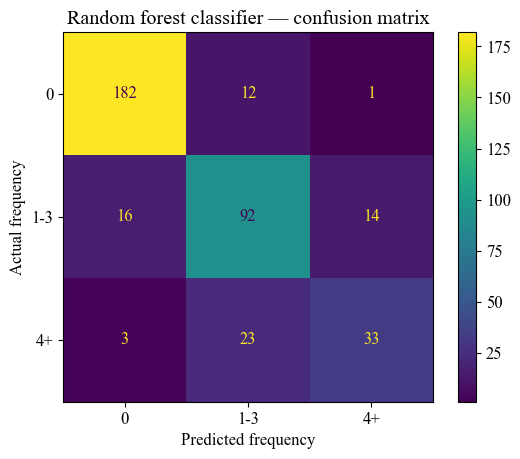

In [78]:
ConfusionMatrixDisplay.from_predictions(
    y_1_test, y_1_pred,
    display_labels=['0', '1-3', '4+']
)
plt.title("Random forest classifier — confusion matrix")
plt.xlabel("Predicted frequency")
plt.ylabel("Actual frequency")
plt.show()

##### 7.1.2.4 Bias/variance diagnostic

The accuracy score calculated on the training dataset is 0.805, and that calculated on the test dataset is 0.816. There therefore appears to be a fairly low bias and a fairly low variance.

#### 7.1.3 Gradient Boosting

##### 7.1.3.1 Choosing parameters

In [79]:
# Using GridSearchCV to find best parameters for RandomForestClassifier model
param_grid = {
    'learning_rate' : [0.05, 0.1],
    'max_depth' : [3, 5, None]
}

grid = GridSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_1_train, y_1_train)

print("Best parameters", grid.best_params_)

Best parameters {'learning_rate': 0.05, 'max_depth': 3}


In [80]:
# Training gradient boosting classifier
boost1 = HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, random_state=42)
boost1.fit(X_1_train, y_1_train)

,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",3
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide `... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dtype""` option... versionchanged:: 1.6 The default value changed from `None` to `""from_dtype""`.",'from_dtyp

##### 7.1.3.2 Train

In [81]:
# Evaluate the gradient boosting classifier on train data with learning_rate=0.05 and max_depth=3
y_1_pred = boost1.predict(X_1_train)

print(classification_report(y_1_train, y_1_pred, target_names=["0", "1-3", "4+"]))

perm_imp = permutation_importance(boost1, X_1_train, y_1_train, n_repeats=5, random_state=42)
importances_boost1 = pd.Series(perm_imp.importances_mean, index=X_1_train.columns)
print(f"\nImportance of each variable\n\n{importances_boost1.sort_values()}")
print(f"\nOverall accuracy: {accuracy_score(y_1_train, y_1_pred)}")

              precision    recall  f1-score   support

           0       0.88      0.91      0.90       612
         1-3       0.67      0.74      0.70       319
          4+       0.77      0.57      0.65       197

    accuracy                           0.80      1128
   macro avg       0.77      0.74      0.75      1128
weighted avg       0.80      0.80      0.80      1128


Importance of each variable

Sex                       -0.000709
Region_South               0.002837
Region_East                0.008511
Region_North               0.051950
Region_Balkans             0.062234
Region_West                0.067376
Age                        0.180142
Education level (ISCED)    0.187411
dtype: float64

Overall accuracy: 0.8023049645390071


##### 7.1.3.3 Test

In [82]:
# Test the gradient boosting classifier
y_1_pred = boost1.predict(X_1_test)

print(classification_report(y_1_test, y_1_pred, target_names=["0", "1-3", "4+"]))

perm_imp = permutation_importance(boost1, X_1_test, y_1_test, n_repeats=5, random_state=42)
importances_boost1 = pd.Series(perm_imp.importances_mean, index=X_1_test.columns)
print(f"\nImportance of each variable\n\n{importances_boost1.sort_values()}")
print(f"\nOverall accuracy: {accuracy_score(y_1_test, y_1_pred)}")

              precision    recall  f1-score   support

           0       0.92      0.92      0.92       195
         1-3       0.71      0.77      0.74       122
          4+       0.67      0.56      0.61        59

    accuracy                           0.82       376
   macro avg       0.77      0.75      0.76       376
weighted avg       0.82      0.82      0.81       376


Importance of each variable

Sex                        0.002660
Region_South               0.015426
Region_East                0.023404
Region_North               0.059574
Region_West                0.063830
Region_Balkans             0.084043
Education level (ISCED)    0.175532
Age                        0.197872
dtype: float64

Overall accuracy: 0.8164893617021277


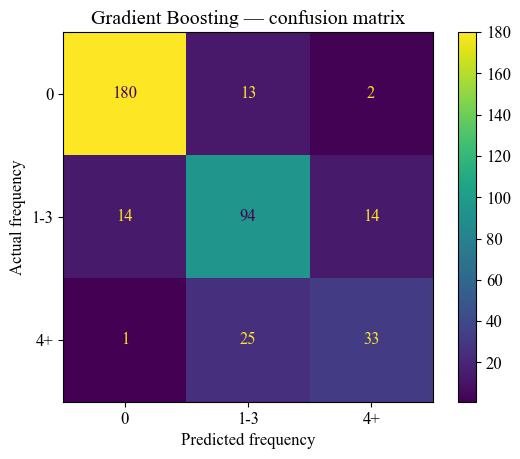

In [83]:
ConfusionMatrixDisplay.from_predictions(
    y_1_test, y_1_pred,
    display_labels=['0', '1-3', '4+']
)
plt.title("Gradient Boosting — confusion matrix")
plt.xlabel("Predicted frequency")
plt.ylabel("Actual frequency")
plt.show()

##### 7.1.3.4 Bias/variance diagnostic

The accuracy score calculated on the training dataset is 0.802, and that calculated on the test dataset is 0.816. There therefore appears to be a fairly low bias and a fairly low variance.

### 7.2 df_economical

#### 7.2.1 Logistic regression

##### 7.2.1.1 Train

In [84]:
# Training logistic regression
reg2 = LogisticRegression(random_state=42)
reg2.fit(X_2_train, y_2_train)

# Logistic regression model summary
coef2 = pd.DataFrame(reg2.coef_, index=["0", "1-3", "4+"], columns=X_2_train.columns)
coef2

,Degree of urbanisation,Income quintile,Household composition_Household with dependent children,Household composition_Household without dependent children,Household composition_One adult,Household composition_One adult 65 years or over,Household composition_One adult with dependent children,Household composition_Three or more adults,Household composition_Two adults,Household composition_Two adults with dependent children,"Household composition_Two adults, at least one aged 65 years or over",Region_Balkans,Region_East,Region_North,Region_South,Region_West
0,-0.421975,-0.913144,-1.131677,0.346995,-0.005876,1.842848,-1.250081,0.495854,0.287544,-1.516263,0.948016,2.624597,0.416976,-2.436049,0.973282,-1.561447
1-3,-0.184850,0.084689,0.901652,-0.348947,-0.378432,-1.100133,0.905273,-0.237010,-0.158005,1.065472,-0.644654,-1.227706,0.027463,1.382569,-0.391364,0.214252
4+,0.606824,0.828454,0.230025,0.001952,0.384308,-0.742715,0.344807,-0.258844,-0.129538,0.450792,-0.303361,-1.396891,-0.444439,1.053480,-0.581919,1.347195


In [85]:
# Evaluate the accuracy and F1 metric for logistic regression model
y_2_pred = reg2.predict(X_2_train)

print(classification_report(y_2_train, y_2_pred, target_names=["0", "1-3", "4+"]))
print(f"\nOverall accuracy: {accuracy_score(y_2_train, y_2_pred)}")

              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1562
         1-3       0.69      0.65      0.67       751
          4+       0.65      0.52      0.58       400

    accuracy                           0.78      2713
   macro avg       0.73      0.69      0.71      2713
weighted avg       0.77      0.78      0.77      2713


Overall accuracy: 0.7788426096572061


##### 7.2.1.2 Test

In [86]:
# Test the logistic regression
y_2_pred = reg2.predict(X_2_test)

print(classification_report(y_2_test, y_2_pred, target_names=["0", "1-3", "4+"]))
print(f"\nOverall accuracy: {accuracy_score(y_2_test, y_2_pred)}")

              precision    recall  f1-score   support

           0       0.85      0.91      0.88       538
         1-3       0.68      0.60      0.64       236
          4+       0.61      0.54      0.57       131

    accuracy                           0.78       905
   macro avg       0.71      0.69      0.70       905
weighted avg       0.77      0.78      0.77       905


Overall accuracy: 0.7779005524861878


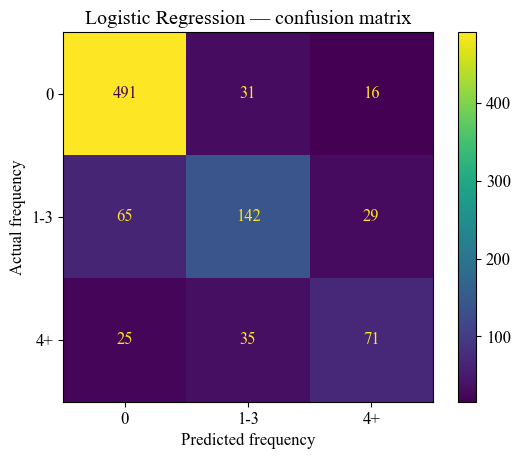

In [87]:
ConfusionMatrixDisplay.from_predictions(
    y_2_test, y_2_pred,
    display_labels=['0', '1-3', '4+']
)
plt.title("Logistic Regression — confusion matrix")
plt.xlabel("Predicted frequency")
plt.ylabel("Actual frequency")
plt.show()

##### 7.2.1.3 Bias/variance diagnostic

The accuracy score calculated on the training dataset is 0.778, and that calculated on the test dataset is 0.777. There therefore appears to be a fairly low bias and a very low variance.

#### 7.2.2 Random forest

##### 7.2.2.1 Choosing parameters

In [88]:
# Using GridSearchCV to find best parameters for RandomForestClassifier model
param_grid = {
    'max_depth' : [3,5,7,None],
    'min_samples_leaf' : [1,5,10,15]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_2_train, y_2_train)

print("Best parameters", grid.best_params_)

Best parameters {'max_depth': None, 'min_samples_leaf': 5}


##### 7.2.2.2 Train

In [89]:
# Training random forest classifier with min_samples_leaf=5
forest = RandomForestClassifier(min_samples_leaf=5, random_state=42)
forest.fit(X_2_train, y_2_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [90]:
# Evaluate the error of random forest classifier
y_2_pred = forest.predict(X_2_train)

print(f"{classification_report(y_2_train, y_2_pred, target_names=['0', '1-3', '4+'])}")

# Importance of each variable
importances2 = pd.Series(forest.feature_importances_, index=X_2_train.columns)
print(f"\nImportance of each variable\n\n{importances2.sort_values()}")

print(f"\nOverall accuracy: {accuracy_score(y_2_train, y_2_pred)}")

              precision    recall  f1-score   support

           0       0.85      0.92      0.88      1562
         1-3       0.70      0.72      0.71       751
          4+       0.76      0.48      0.59       400

    accuracy                           0.80      2713
   macro avg       0.77      0.71      0.73      2713
weighted avg       0.79      0.80      0.79      2713


Importance of each variable

Household composition_One adult with dependent children                 0.003409
Household composition_Two adults                                        0.009750
Household composition_Household without dependent children              0.010344
Household composition_Three or more adults                              0.010875
Household composition_One adult                                         0.013436
Household composition_Two adults, at least one aged 65 years or over    0.020358
Household composition_One adult 65 years or over                        0.025030
Region_Balkans        

##### 7.2.2.3 Test

In [91]:
# Test the random forest classifier
y_2_pred = forest.predict(X_2_test)

print(f"{classification_report(y_2_test, y_2_pred, target_names=['0', '1-3', '4+'])}")

# Importance of each variable
importances2 = pd.Series(forest.feature_importances_, index=X_2_test.columns)
print(f"\nImportance of each variable\n\n{importances2.sort_values()}")

print(f"\nOverall accuracy: {accuracy_score(y_2_test, y_2_pred)}")

              precision    recall  f1-score   support

           0       0.85      0.89      0.87       538
         1-3       0.62      0.63      0.62       236
          4+       0.66      0.48      0.56       131

    accuracy                           0.76       905
   macro avg       0.71      0.67      0.68       905
weighted avg       0.76      0.76      0.76       905


Importance of each variable

Household composition_One adult with dependent children                 0.003409
Household composition_Two adults                                        0.009750
Household composition_Household without dependent children              0.010344
Household composition_Three or more adults                              0.010875
Household composition_One adult                                         0.013436
Household composition_Two adults, at least one aged 65 years or over    0.020358
Household composition_One adult 65 years or over                        0.025030
Region_Balkans        

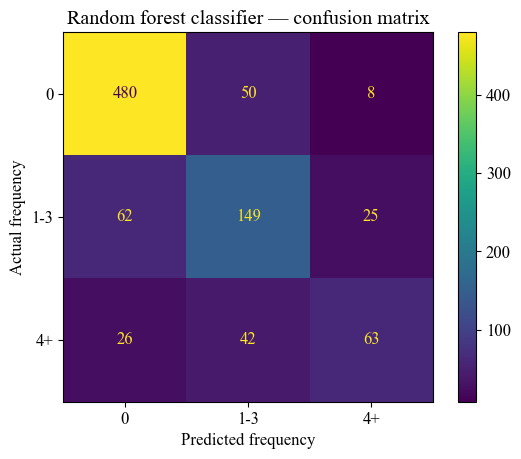

In [92]:
ConfusionMatrixDisplay.from_predictions(
    y_2_test, y_2_pred,
    display_labels=['0', '1-3', '4+']
)
plt.title("Random forest classifier — confusion matrix")
plt.xlabel("Predicted frequency")
plt.ylabel("Actual frequency")
plt.show()

##### 7.2.2.4 Bias/variance diagnostic

In [ ]:
%%sql


The accuracy score calculated on the training dataset is 0.797, and that calculated on the test dataset is 0.764. There therefore appears to be a fairly low bias and a high variance.

#### 7.2.3 Gradient Boosting

##### 7.2.3.1 Choosing parameters

In [93]:
# Using GridSearchCV to find best parameters for RandomForestClassifier model
param_grid = {
    'learning_rate' : [0.05, 0.1],
    'max_depth' : [3, 5, None]
}

grid = GridSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_2_train, y_2_train)

print("Best parameters", grid.best_params_)

Best parameters {'learning_rate': 0.1, 'max_depth': 3}


In [94]:
# Training gradient boosting classifier
boost2 = HistGradientBoostingClassifier(learning_rate=0.1, max_depth=3, random_state=42)
boost2.fit(X_2_train, y_2_train)

,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",3
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide `... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dtype""` option... versionchanged:: 1.6 The default value changed from `None` to `""from_dtype""`.",'from_dtype

##### 7.2.3.2 Train

In [95]:
# Evaluate the gradient boosting classifier on train data
y_2_pred = boost2.predict(X_2_train)

print(classification_report(y_2_train, y_2_pred, target_names=["0", "1-3", "4+"]))

perm_imp = permutation_importance(boost2, X_2_train, y_2_train, n_repeats=5, random_state=42)
importances_boost2 = pd.Series(perm_imp.importances_mean, index=X_2_train.columns)
print(f"\nImportance of each variable\n\n{importances_boost2.sort_values()}")
print(f"\nOverall accuracy: {accuracy_score(y_2_train, y_2_pred)}")

              precision    recall  f1-score   support

           0       0.85      0.91      0.88      1562
         1-3       0.69      0.69      0.69       751
          4+       0.70      0.51      0.59       400

    accuracy                           0.79      2713
   macro avg       0.75      0.70      0.72      2713
weighted avg       0.78      0.79      0.78      2713


Importance of each variable

Household composition_Household without dependent children             -7.371913e-05
Region_East                                                            -4.440892e-17
Household composition_Three or more adults                              9.583487e-04
Household composition_One adult                                         2.580170e-03
Household composition_One adult with dependent children                 3.464799e-03
Household composition_Two adults                                        4.054552e-03
Region_South                                                            8.99373

##### 7.2.3.3 Test

In [96]:
# Test the gradient boosting classifier
y_2_pred = boost2.predict(X_2_test)

print(classification_report(y_2_test, y_2_pred, target_names=["0", "1-3", "4+"]))

perm_imp = permutation_importance(boost2, X_2_test, y_2_test, n_repeats=5, random_state=42)
importances_boost2 = pd.Series(perm_imp.importances_mean, index=X_2_test.columns)
print(f"\nImportance of each variable\n\n{importances_boost2.sort_values()}")
print(f"\nOverall accuracy: {accuracy_score(y_2_test, y_2_pred)}")

              precision    recall  f1-score   support

           0       0.85      0.90      0.88       538
         1-3       0.65      0.63      0.64       236
          4+       0.63      0.50      0.56       131

    accuracy                           0.77       905
   macro avg       0.71      0.68      0.69       905
weighted avg       0.77      0.77      0.77       905


Importance of each variable

Household composition_Household without dependent children             -0.001768
Household composition_Two adults                                       -0.000884
Household composition_One adult                                         0.001768
Household composition_Two adults, at least one aged 65 years or over    0.003978
Region_East                                                             0.005083
Household composition_One adult with dependent children                 0.006409
Household composition_Three or more adults                              0.006630
Region_South          

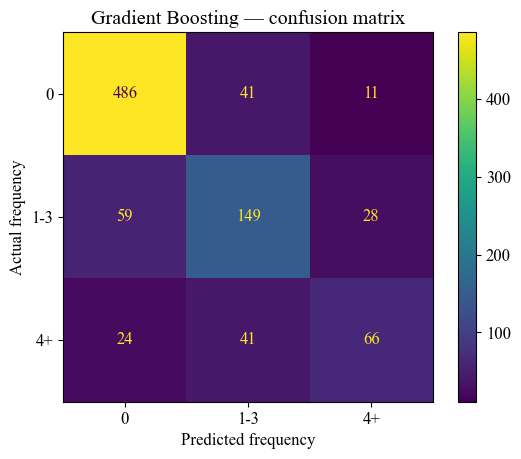

In [97]:
ConfusionMatrixDisplay.from_predictions(
    y_2_test, y_2_pred,
    display_labels=['0', '1-3', '4+']
)
plt.title("Gradient Boosting — confusion matrix")
plt.xlabel("Predicted frequency")
plt.ylabel("Actual frequency")
plt.show()

##### 7.2.3.4 Bias/variance diagnostic

The accuracy score calculated on the training dataset is 0.790, and that calculated on the test dataset is 0.774. There therefore appears to be a fairly low bias and a fairly low variance. 